# Step 1: Data Loading & Inspection
Importing necessary libraries and loading the Superstore dataset to check initial structure and missing values.

In [2]:
# 1. Import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load the dataset
# We use encoding='latin1' because this dataset often contains special characters (like quotes) that cause errors with default encoding.
# Make sure the filename matches exactly what is in your folder.
df = pd.read_csv('superstore_sales (1).csv', encoding='latin1')

# 3. Inspect the structure of the data
print("Shape of the dataset (Rows, Columns):", df.shape)
print("\n--- Data Types and Missing Values ---")
df.info()

# 4. Check for missing values specifically
print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

# 5. Look at the first 5 rows
df.head()

Shape of the dataset (Rows, Columns): (10800, 21)

--- Data Types and Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Produ

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


# Step 2: Data Wrangling & Feature Engineering
Parsing Order Dates into datetime format and extracting Year and Month features for seasonality analysis.

In [3]:
# Convert Order Date to actual datetime objects
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Extract Year and Month for seasonality analysis
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

# Let's verify it worked
print("Date types successfully converted:")
print(df[['Order Date', 'Year', 'Month']].head())

Date types successfully converted:
  Order Date    Year  Month
0 2017-11-08  2017.0   11.0
1 2017-11-08  2017.0   11.0
2 2017-06-12  2017.0    6.0
3 2016-10-11  2016.0   10.0
4 2016-10-11  2016.0   10.0


# Step 3: Aggregate Analysis (Category, Region, Segment)
Calculating total Sales and Profit to identify high-revenue areas and potential margin issues.

In [4]:
# 1. Revenue & Profit by Category
category_stats = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
print("\n--- Sales and Profit by Category ---")
print(category_stats)

# 2. Revenue & Profit by Region
region_stats = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
print("\n--- Sales and Profit by Region ---")
print(region_stats)

# 3. Revenue & Profit by Customer Segment
segment_stats = df.groupby('Segment')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
print("\n--- Sales and Profit by Segment ---")
print(segment_stats)


--- Sales and Profit by Category ---
                       Sales       Profit
Category                                 
Technology       836154.0330  145454.9481
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008

--- Sales and Profit by Region ---
               Sales       Profit
Region                           
West     725457.8245  108418.4489
East     678781.2400   91522.7800
Central  501239.8908   39706.3625
South    391721.9050   46749.4303

--- Sales and Profit by Segment ---
                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


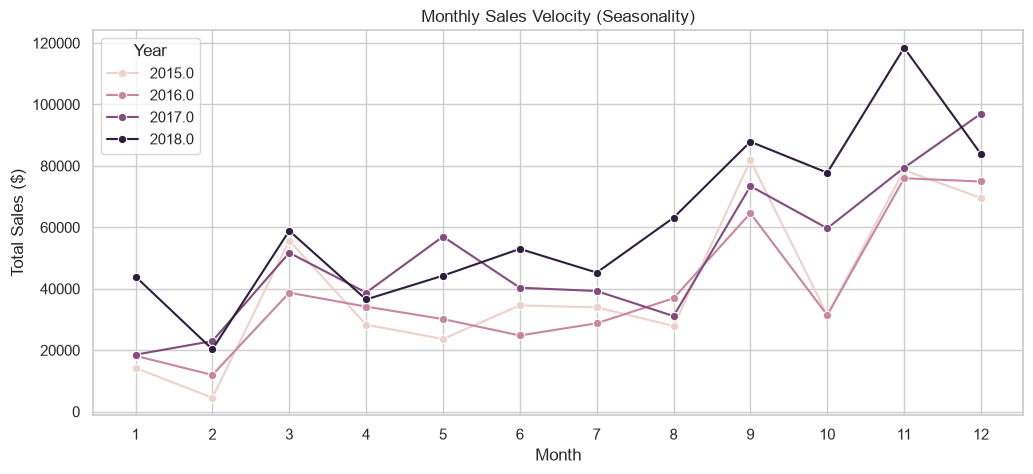

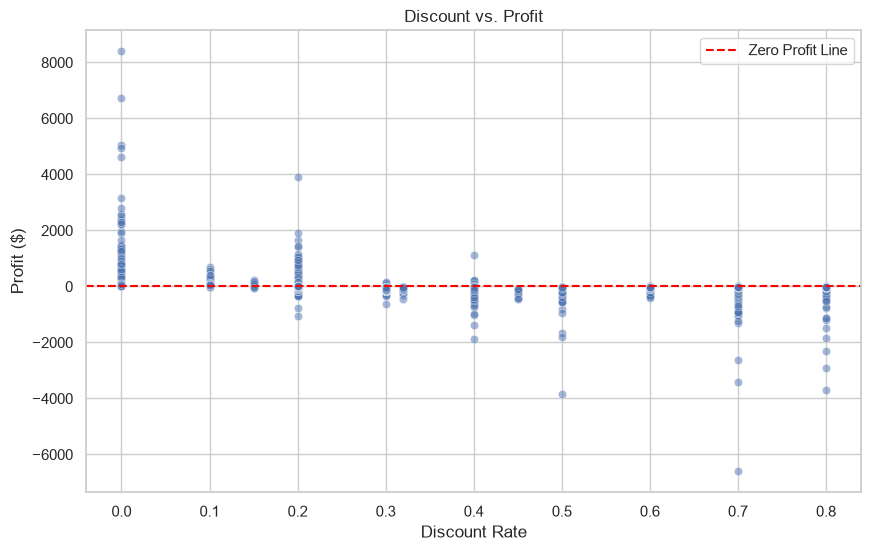

In [5]:
# Set the visual style for better looking charts
sns.set_theme(style="whitegrid")

# --- Chart 1: Monthly Sales Velocity ---
plt.figure(figsize=(12, 5))
# Group by Year and Month to see the trend over time
monthly_sales = df.groupby(['Year', 'Month'])['Sales'].sum().reset_index()
sns.lineplot(data=monthly_sales, x='Month', y='Sales', hue='Year', marker='o')
plt.title('Monthly Sales Velocity (Seasonality)')
plt.ylabel('Total Sales ($)')
plt.xlabel('Month')
plt.xticks(range(1, 13)) # Ensure all months (1-12) are shown
plt.legend(title='Year')
plt.show()

# --- Chart 2: Discount vs. Profit Scatter Plot ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5)
plt.title('Discount vs. Profit')
plt.axhline(0, color='red', linestyle='--', label='Zero Profit Line') # Red line at $0
plt.ylabel('Profit ($)')
plt.xlabel('Discount Rate')
plt.legend()
plt.show()

# Executive Takeaways: Superstore EDA

Based on the exploratory data analysis, here are 5 key business findings:

1. Seasonality & Sales Velocity: Sales show a strong seasonal trend, consistently peaking in the final quarter of the year (specifically [Month, e.g., November] and [Month, e.g., December]), while the first quarter (Jan-Feb) experiences a significant dip. This suggests the business should prepare inventory and marketing efforts for a Q4 surge.

2. Category Profitability Discrepancy: While [Category Name, e.g., Technology] generates the highest total sales (~$836k), it is not the most efficient. [Category Name, e.g., Furniture] has high sales volume but very low total profit (~$18k), indicating severe margin issues in that specific category.

3. Discount Sensitivity & Profit Loss: The scatter plot clearly demonstrates that heavy discounting is destroying profitability. Discounts above [X%, e.g., 20%] almost universally result in negative profit, regardless of the product.

4. Regional Performance: The [Region Name, e.g., West] region is the highest revenue generator and also yields the highest profit. Conversely, the [Region Name, e.g., South] region lags significantly behind in both metrics.

5. Customer Segment Focus: The [Segment Name, e.g., Consumer] segment is the primary driver of revenue (over $1.1M in sales). However, the [Segment Name, e.g., Corporate] segment shows a solid profit margin and should be a focus for growth.